# Transformer language identification: fine-tuning and robustness test (v2)

Fine-tunes a multilingual transformer on the **clean** training sentences (`nb_train.csv`), tests it on the
**same** test sentences as Naive Bayes and fastText (`nb_test.csv`) with the same perturbation grid, and then tests it
on real informal comments. At the end **one zip file** with all results is downloaded.

**Before you start**
1. Runtime > Change runtime type > **T4 GPU**.
2. Choose the model in the settings cell (`MODEL_NAME`). Learning rate and batch size are set automatically.
3. Runtime > **Restart session and run all**. When asked, upload `nb_train.csv` and `nb_test.csv`.
4. To test another model: change `MODEL_NAME`, then Restart session and run all again (this frees the GPU memory).
5. Unzip the downloaded file into the folder of `informal_eval.py` on your computer. Do not commit `informal_ro.txt` to git.

In [ ]:
!pip -q install -U transformers

In [ ]:
# ----------------------------------------------------------------- settings
# Models used in the project: "distilbert-base-multilingual-cased" (135 M), "xlm-roberta-base" (278 M),
# "xlm-roberta-large" (560 M). Run one model per session.
#MODEL_NAME = "xlm-roberta-base"
#MODEL_NAME = 'distilbert-base-multilingual-cased'
MODEL_NAME = 'xlm-roberta-large'

# Learning rate and batch size per model (xlm-roberta-large needs a smaller learning rate and batch).
PRESETS = {
    "distilbert-base-multilingual-cased": (2e-5, 16),
    "xlm-roberta-base": (2e-5, 16),
    "xlm-roberta-large": (1e-5, 8),
}
LR_OVERRIDE = None       # set a number to replace the preset learning rate
BATCH_OVERRIDE = 4    # set a number (e.g. 4) if the GPU runs out of memory
LR, BATCH_SIZE = PRESETS.get(MODEL_NAME, (2e-5, 16))
if LR_OVERRIDE:
    LR = LR_OVERRIDE
if BATCH_OVERRIDE:
    BATCH_SIZE = BATCH_OVERRIDE

EPOCHS = 2
MAX_LEN = 128        # sentences longer than 128 tokens are truncated
SEED = 0

DIAC_FRACTIONS = (0.0, 0.25, 0.5, 0.75, 1.0)        # share of diacritics removed
TYPO_RATES = (0.0, 0.05, 0.10, 0.20, 0.30, 0.40)    # share of letters hit by a typo
N_SEEDS = 5          # repetitions for random conditions (lower it, e.g. 3, if it is too slow)
N_BOOTSTRAP = 1000
TRUNCATE_CHARS = None    # e.g. 40 -> cut every Romanian test sentence to its first 40 characters

# QUICK RUN on a CPU (smoke test only, do not report these numbers):
#   TRAIN_SUBSET = 1600, EPOCHS = 1, MAX_LEN = 64, N_SEEDS = 2, EVAL_SUBSET = 100
TRAIN_SUBSET = None      # e.g. 1600 -> train on a stratified subset of the training sentences
EVAL_SUBSET = None       # e.g. 100  -> use only the first 100 Romanian test sentences in the grid
print("model:", MODEL_NAME, "| learning rate:", LR, "| batch size:", BATCH_SIZE)
# -------------------------------------------------------------------------

model: xlm-roberta-large | learning rate: 1e-05 | batch size: 4


In [ ]:
from pathlib import Path

if not (Path("nb_train.csv").exists() and Path("nb_test.csv").exists()):
    from google.colab import files
    files.upload()      # select nb_train.csv and nb_test.csv
print(sorted(p.name for p in Path(".").glob("nb_*.csv")))

Saving nb_test.csv to nb_test.csv
Saving nb_train.csv to nb_train.csv
['nb_test.csv', 'nb_train.csv']


## Perturbation functions (identical to the ones used for fastText and Naive Bayes)

In [ ]:
import collections
import random

import numpy as np
import pandas as pd

LETTERS = "abcdefghijklmnopqrstuvwxyz"
STRIP = str.maketrans({
    "\u0103": "a", "\u0102": "A", "\u00e2": "a", "\u00c2": "A",
    "\u00ee": "i", "\u00ce": "I",
    "\u0219": "s", "\u0218": "S", "\u015f": "s", "\u015e": "S",
    "\u021b": "t", "\u021a": "T", "\u0163": "t", "\u0162": "T",
})


def char_noise(text, p, rnd):
    """Each letter is hit with probability p: delete, substitute, insert or swap."""
    chars, out, i = list(text), [], 0
    while i < len(chars):
        c = chars[i]
        if c.isalpha() and rnd.random() < p:
            op = rnd.choice(("del", "sub", "ins", "swap"))
            if op == "del":
                pass
            elif op == "sub":
                out.append(rnd.choice(LETTERS))
            elif op == "ins":
                out.extend([c, rnd.choice(LETTERS)])
            elif op == "swap" and i + 1 < len(chars):
                out.extend([chars[i + 1], c])
                i += 1
            else:
                out.append(c)
        else:
            out.append(c)
        i += 1
    return "".join(out)


def partial_strip(text, fraction, rnd):
    """Remove each Romanian diacritic with probability `fraction`."""
    if fraction <= 0:
        return text
    out = []
    for ch in text:
        if ord(ch) in STRIP and (fraction >= 1 or rnd.random() < fraction):
            out.append(STRIP[ord(ch)])
        else:
            out.append(ch)
    return "".join(out)


def perturb(text, diac_fraction, typo_rate, rnd):
    text = partial_strip(text, diac_fraction, rnd)
    if typo_rate > 0:
        text = char_noise(text, typo_rate, rnd)
    return text

## Data, model and tokenizer

In [ ]:
import torch
from sklearn.model_selection import train_test_split
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU found - full training is very slow on a CPU. Use Google Colab (T4 GPU) "
          "or the quick-run settings (TRAIN_SUBSET, EPOCHS=1, MAX_LEN=64, N_SEEDS=2, EVAL_SUBSET).")

train_all = pd.read_csv("nb_train.csv")
test = pd.read_csv("nb_test.csv")
LANGS = sorted(train_all["lang"].unique())
LANG2ID = {l: i for i, l in enumerate(LANGS)}
ID2LANG = {i: l for l, i in LANG2ID.items()}

# 10 % of the training sentences are used for validation (the test set stays untouched)
train, val = train_test_split(train_all, test_size=0.1, stratify=train_all["lang"], random_state=SEED)
if TRAIN_SUBSET and TRAIN_SUBSET < len(train):
    train = train_test_split(train, train_size=TRAIN_SUBSET, stratify=train["lang"], random_state=SEED)[0]
print(len(train), "train /", len(val), "validation /", len(test), "test sentences;", LANGS)

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LANGS), id2label=ID2LANG, label2id=LANG2ID).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params / 1e6:.0f} M parameters")

device: cuda
5760 train / 640 validation / 1600 test sentences; ['es', 'fr', 'it', 'ro']


config.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/389 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-large
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


xlm-roberta-large: 560 M parameters


In [ ]:
@torch.no_grad()
def predict_proba(sentences, batch_size=64):
    model.eval()
    sentences = list(sentences)
    out = []
    for i in range(0, len(sentences), batch_size):
        enc = tok(sentences[i:i + batch_size], padding=True, truncation=True,
                  max_length=MAX_LEN, return_tensors="pt").to(device)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
            logits = model(**enc).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)


def accuracy(df):
    pred = predict_proba(df["text"]).argmax(axis=1)
    return float((pred == df["lang"].map(LANG2ID).values).mean())

## Training (clean sentences only)

In [ ]:
import time

def train_model():
    texts = train["text"].tolist()
    y = train["lang"].map(LANG2ID).values
    steps = EPOCHS * ((len(texts) + BATCH_SIZE - 1) // BATCH_SIZE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
    scaler = torch.amp.GradScaler("cuda", enabled=(device == "cuda"))
    rng = np.random.default_rng(SEED)
    t0 = time.time()
    for epoch in range(EPOCHS):
        model.train()
        order = rng.permutation(len(texts))
        total, n_batches = 0.0, 0
        for i in range(0, len(order), BATCH_SIZE):
            idx = order[i:i + BATCH_SIZE]
            enc = tok([texts[j] for j in idx], padding=True, truncation=True,
                      max_length=MAX_LEN, return_tensors="pt").to(device)
            y_batch = torch.tensor(y[idx]).to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                loss = model(**enc, labels=y_batch).loss
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            total += loss.item()
            n_batches += 1
            if n_batches % 25 == 0:
                print(f"  epoch {epoch + 1}: batch {n_batches}/{(len(texts) + BATCH_SIZE - 1) // BATCH_SIZE}  "
                      f"loss={total / n_batches:.4f}  ({time.time() - t0:.0f} s)", flush=True)
        print(f"epoch {epoch + 1}/{EPOCHS}  loss={total / n_batches:.4f}  "
              f"validation accuracy={accuracy(val):.4f}  ({time.time() - t0:.0f} s)")

train_model()

  epoch 1: batch 25/1440  loss=1.3908  (10 s)
  epoch 1: batch 50/1440  loss=1.3710  (18 s)
  epoch 1: batch 75/1440  loss=1.3650  (26 s)
  epoch 1: batch 100/1440  loss=1.3044  (34 s)
  epoch 1: batch 125/1440  loss=1.1647  (42 s)
  epoch 1: batch 150/1440  loss=1.0031  (52 s)
  epoch 1: batch 175/1440  loss=0.8696  (60 s)
  epoch 1: batch 200/1440  loss=0.7644  (69 s)
  epoch 1: batch 225/1440  loss=0.6804  (78 s)
  epoch 1: batch 250/1440  loss=0.6128  (87 s)
  epoch 1: batch 275/1440  loss=0.5573  (95 s)
  epoch 1: batch 300/1440  loss=0.5110  (103 s)
  epoch 1: batch 325/1440  loss=0.4718  (112 s)
  epoch 1: batch 350/1440  loss=0.4382  (120 s)
  epoch 1: batch 375/1440  loss=0.4090  (128 s)
  epoch 1: batch 400/1440  loss=0.3834  (137 s)
  epoch 1: batch 425/1440  loss=0.3609  (145 s)
  epoch 1: batch 450/1440  loss=0.3409  (153 s)
  epoch 1: batch 475/1440  loss=0.3230  (161 s)
  epoch 1: batch 500/1440  loss=0.3068  (169 s)
  epoch 1: batch 525/1440  loss=0.2922  (178 s)
  epoc

## Clean test set (all four languages)

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

pred = predict_proba(test["text"]).argmax(axis=1)
true = test["lang"].map(LANG2ID).values
print(classification_report(true, pred, target_names=LANGS, digits=3))
print(pd.DataFrame(confusion_matrix(true, pred), index=[f"true_{l}" for l in LANGS],
                   columns=[f"pred_{l}" for l in LANGS]))

              precision    recall  f1-score   support

          es      1.000     1.000     1.000       400
          fr      1.000     1.000     1.000       400
          it      1.000     1.000     1.000       400
          ro      1.000     1.000     1.000       400

    accuracy                          1.000      1600
   macro avg      1.000     1.000     1.000      1600
weighted avg      1.000     1.000     1.000      1600

         pred_es  pred_fr  pred_it  pred_ro
true_es      400        0        0        0
true_fr        0      400        0        0
true_it        0        0      400        0
true_ro        0        0        0      400


## Robustness grid on the Romanian test sentences

`accuracy_ro` = share of Romanian test sentences predicted as Romanian. `mean_p_ro` = average probability given to
Romanian (not comparable with Naive Bayes margins or fastText confidence). The 95 % interval comes from resampling
the sentences 1000 times.

In [ ]:
def bootstrap_ci(values, rng):
    n = len(values)
    idx = rng.integers(0, n, size=(N_BOOTSTRAP, n))
    return np.percentile(values[idx].mean(axis=1), [2.5, 97.5])


def evaluate_condition(sentences, diac_fraction, typo_rate, label):
    deterministic = (diac_fraction in (0.0, 1.0)) and typo_rate == 0.0
    n_seeds = 1 if deterministic else N_SEEDS
    ro_id = LANG2ID["ro"]
    correct = np.zeros((n_seeds, len(sentences)))
    p_ro, wrong = [], collections.Counter()
    for s in range(n_seeds):
        rnd = random.Random(f"{label}-{s}")
        perturbed = [perturb(t, diac_fraction, typo_rate, rnd) for t in sentences]
        proba = predict_proba(perturbed)
        pred = proba.argmax(axis=1)
        correct[s] = (pred == ro_id)
        p_ro.append(float(proba[:, ro_id].mean()))
        wrong.update(ID2LANG[int(p)] for p in pred if p != ro_id)
    per_sentence = correct.mean(axis=0)
    low, high = bootstrap_ci(per_sentence, np.random.default_rng(SEED))
    seed_acc = correct.mean(axis=1)
    return {
        "diacritics_removed": diac_fraction, "typo_rate": typo_rate,
        "accuracy_ro": round(float(seed_acc.mean()), 4),
        "ci_low": round(float(low), 4), "ci_high": round(float(high), 4),
        "std_over_seeds": round(float(seed_acc.std()), 4),
        "mean_p_ro": round(float(np.mean(p_ro)), 4),
        "top_confusions": dict(wrong.most_common(3)),
    }

In [ ]:
ro = test.loc[test["lang"] == "ro", "text"].tolist()
if EVAL_SUBSET:
    ro = ro[:EVAL_SUBSET]
if TRUNCATE_CHARS:
    ro = [s[:TRUNCATE_CHARS] for s in ro]
    print(f"Romanian test sentences cut to the first {TRUNCATE_CHARS} characters")
print(f"Evaluating on {len(ro)} Romanian test sentences")

rows = []
for f in DIAC_FRACTIONS:
    for p in TYPO_RATES:
        rows.append(evaluate_condition(ro, f, p, f"d{f}-t{p}"))
    print(f"diacritics_removed={int(f * 100)}% done")

res = pd.DataFrame(rows)
res.insert(0, "n_params_million", round(n_params / 1e6))
res.insert(0, "model", MODEL_NAME)
acc = res.pivot(index="diacritics_removed", columns="typo_rate", values="accuracy_ro")
conf = res.pivot(index="diacritics_removed", columns="typo_rate", values="mean_p_ro")

Evaluating on 400 Romanian test sentences
diacritics_removed=0% done
diacritics_removed=25% done
diacritics_removed=50% done
diacritics_removed=75% done
diacritics_removed=100% done


## Results

In [ ]:
print("ACCURACY (rows = share of diacritics removed, columns = typo rate)")
display(acc.style.format("{:.3f}").background_gradient(cmap="viridis", axis=None, vmin=0, vmax=1))
print("MEAN PROBABILITY OF ROMANIAN")
display(conf.style.format("{:.3f}").background_gradient(cmap="viridis", axis=None, vmin=0, vmax=1))
display(res)

ACCURACY (rows = share of diacritics removed, columns = typo rate)


typo_rate,0.000000,0.050000,0.100000,0.200000,0.300000,0.400000
diacritics_removed,,,,,,
0.000000,1.000,1.000,1.000,1.000,0.996,0.990
0.250000,1.000,1.000,1.000,0.998,0.992,0.974
0.500000,1.000,1.000,1.000,0.995,0.985,0.946
0.750000,1.000,1.000,0.999,0.989,0.960,0.894
1.000000,1.000,1.000,0.998,0.971,0.879,0.745


MEAN PROBABILITY OF ROMANIAN


typo_rate,0.000000,0.050000,0.100000,0.200000,0.300000,0.400000
diacritics_removed,,,,,,
0.000000,1.000,1.000,1.000,0.999,0.995,0.987
0.250000,1.000,1.000,1.000,0.997,0.990,0.969
0.500000,1.000,1.000,0.999,0.994,0.980,0.940
0.750000,1.000,1.000,0.999,0.986,0.953,0.872
1.000000,1.000,1.000,0.998,0.968,0.862,0.700


,model,n_params_million,diacritics_removed,typo_rate,accuracy_ro,ci_low,ci_high,std_over_seeds,mean_p_ro,top_confusions
0,xlm-roberta-large,560,0.00,0.00,1.0000,1.0000,1.0000,0.0000,1.0000,{}
1,xlm-roberta-large,560,0.00,0.05,1.0000,1.0000,1.0000,0.0000,1.0000,{}
2,xlm-roberta-large,560,0.00,0.10,1.0000,1.0000,1.0000,0.0000,0.9999,{}
3,xlm-roberta-large,560,0.00,0.20,0.9995,0.9985,1.0000,0.0010,0.9989,{'it': 1}
4,xlm-roberta-large,560,0.00,0.30,0.9960,0.9920,0.9990,0.0020,0.9953,"{'es': 4, 'it': 3, 'fr': 1}"
5,xlm-roberta-large,560,0.00,0.40,0.9900,0.9840,0.9950,0.0057,0.9872,"{'it': 10, 'es': 9, 'fr': 1}"
6,xlm-roberta-large,560,0.25,0.00,1.0000,1.0000,1.0000,0.0000,1.0000,{}
7,xlm-roberta-large,560,0.25,0.05,1.0000,1.0000,1.0000,0.0000,0.9999,{}
8,xlm-roberta-large,560,0.25,0.10,1.0000,1.0000,1.0000,0.0000,1.0000,{}
9,xlm-roberta-large,560,0.25,0.20,0.9975,0.9945,0.9995,0.0022,0.9968,"{'it': 3, 'es': 2}"


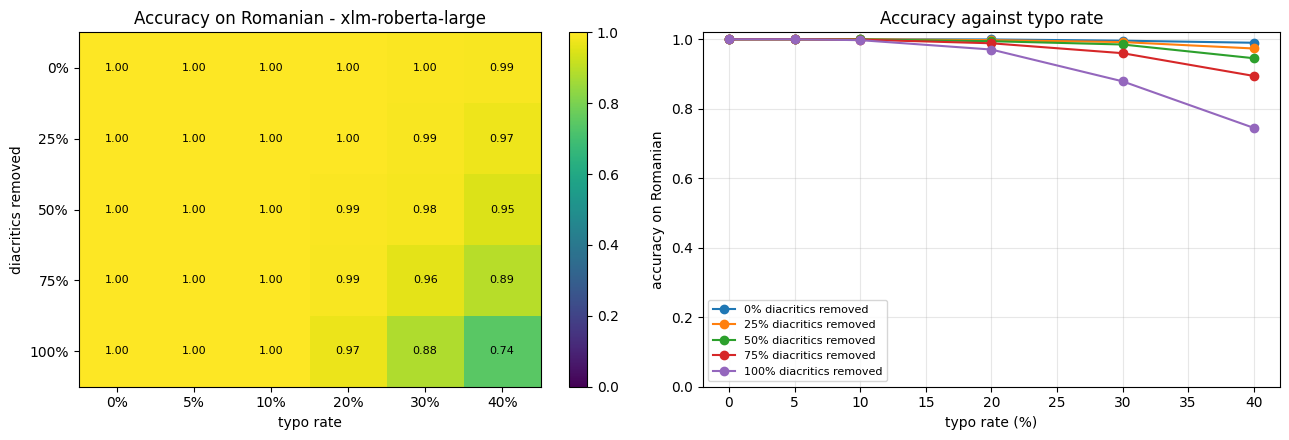

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
im = ax[0].imshow(acc.values, vmin=0, vmax=1, cmap="viridis", aspect="auto")
ax[0].set_xticks(range(len(acc.columns)), [f"{int(c * 100)}%" for c in acc.columns])
ax[0].set_yticks(range(len(acc.index)), [f"{int(i * 100)}%" for i in acc.index])
ax[0].set_xlabel("typo rate"); ax[0].set_ylabel("diacritics removed")
ax[0].set_title(f"Accuracy on Romanian - {MODEL_NAME}")
for i in range(acc.shape[0]):
    for j in range(acc.shape[1]):
        v = acc.values[i, j]
        ax[0].text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.6 else "black", fontsize=8)
fig.colorbar(im, ax=ax[0])

for f in DIAC_FRACTIONS:
    sub = res[res["diacritics_removed"] == f]
    ax[1].plot(sub["typo_rate"] * 100, sub["accuracy_ro"], marker="o", label=f"{int(f * 100)}% diacritics removed")
ax[1].set_xlabel("typo rate (%)"); ax[1].set_ylabel("accuracy on Romanian")
ax[1].set_ylim(0, 1.02); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
ax[1].set_title("Accuracy against typo rate")
plt.tight_layout()
name = MODEL_NAME.replace("/", "_")
plt.savefig(f"transformer_{name}_grid.png", dpi=200)
plt.show()

## Save the grid results (they are downloaded in the zip file at the end)

In [ ]:
csv_name = f"transformer_{MODEL_NAME.replace('/', '_')}_results.csv"
res.to_csv(csv_name, index=False)
print("saved", csv_name, "and transformer_" + MODEL_NAME.replace('/', '_') + "_grid.png")

saved transformer_xlm-roberta-large_results.csv and transformer_xlm-roberta-large_grid.png


## Informal text: real Facebook comments (domain shift)

The model was trained on clean parliament sentences. Here it is tested on real Romanian comments
(`readerbench/ro-fb-offense`). The labels are **assumed** Romanian, not verified. Keep the raw comments out of git.

In [ ]:
!pip -q install datasets
from datasets import load_dataset

INFORMAL_MAX = 2000
REVIEWS_FILE = None          # optional: name of an uploaded LaRoSeDa .csv/.parquet file, e.g. "laroseda_train.csv"
TEXT_COLUMNS = ("text", "content", "sentence", "review", "comment", "tweet")


def pick_texts(df, max_n=INFORMAL_MAX):
    col = next((c for c in TEXT_COLUMNS if c in df.columns), None)
    if col is None:   # fall back to the column with the longest strings
        col = max((c for c in df.columns if df[c].dtype == object),
                  key=lambda c: df[c].astype(str).str.len().mean())
    print(f"  columns={list(df.columns)}, using '{col}', {len(df)} rows")
    texts = [" ".join(t.split()) for t in df[col] if isinstance(t, str) and len(t.strip()) >= 10]
    texts = list(dict.fromkeys(texts))          # remove duplicates, keep order
    random.Random(0).shuffle(texts)
    return texts[:max_n]


informal = {}
print("readerbench/ro-fb-offense")
ds = load_dataset("readerbench/ro-fb-offense")
informal["offensive_comments"] = pick_texts(pd.concat([ds[s].to_pandas() for s in ds], ignore_index=True))

if REVIEWS_FILE:
    print(REVIEWS_FILE)
    df = pd.read_parquet(REVIEWS_FILE) if REVIEWS_FILE.endswith(".parquet") else pd.read_csv(REVIEWS_FILE)
    informal["reviews"] = pick_texts(df)

for k, v in informal.items():
    print(k, len(v), "comments; example:", v[:2])

readerbench/ro-fb-offense


README.md:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/297k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/3564 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/891 [00:00<?, ? examples/s]

  columns=['sender', 'no_reacts', 'text', 'label'], using 'text', 4455 rows
offensive_comments 2000 comments; example: ['D-Zeu Chiar ca trimite moartea dupa cei prosti,oi,hiene,Globalisti si prostituati', 'Unde ai lucrat ?']


In [ ]:
DIAC = set("ăâîșțĂÂÎȘȚşţŞŢ")
ro_id = LANG2ID["ro"]


def evaluate_informal(name, texts):
    proba = predict_proba(texts)
    pred = proba.argmax(axis=1)
    correct = (pred == ro_id)
    has_dia = np.array([any(c in DIAC for c in t) for t in texts])
    wrong = collections.Counter(ID2LANG[int(p)] for p in pred if p != ro_id)
    row = {
        "dataset": name, "n": len(texts),
        "accuracy_ro": round(float(correct.mean()), 4),
        "mean_p_ro": round(float(proba[:, ro_id].mean()), 4),
        "share_with_diacritics": round(float(has_dia.mean()), 3),
        "acc_with_diacritics": round(float(correct[has_dia].mean()), 4) if has_dia.any() else None,
        "acc_without_diacritics": round(float(correct[~has_dia].mean()), 4) if (~has_dia).any() else None,
        "median_chars": int(np.median([len(t) for t in texts])),
        "top_confusions": dict(wrong.most_common(3)),
    }
    return row, [t for t, c in zip(texts, correct) if not c][:10]


rows, errors = [], {}
for name, texts in informal.items():
    if texts:
        row, errs = evaluate_informal(name, texts)
        rows.append(row); errors[name] = errs

informal_res = pd.DataFrame(rows)
informal_res.insert(0, "model", MODEL_NAME)
display(informal_res)
for name, errs in errors.items():
    print(f"\nMisclassified examples from {name} (look at them by hand, do not copy many into the paper):")
    for t in errs:
        print("  -", t[:150])
informal_res.to_csv(f"informal_{MODEL_NAME.replace('/', '_')}_results.csv", index=False)

,model,dataset,n,accuracy_ro,mean_p_ro,share_with_diacritics,acc_with_diacritics,acc_without_diacritics,median_chars,top_confusions
0,xlm-roberta-large,offensive_comments,2000,0.9365,0.9339,0.554,0.9964,0.8621,48,"{'it': 78, 'es': 33, 'fr': 16}"



Misclassified examples from offensive_comments (look at them by hand, do not copy many into the paper):
  - Romanii vor neutralitate !!!
  - Huuooo Satanelor
  - Americani ne-a distrut tara ce vb
  - Respect magistrat Angelo Giorgiani..
  - Vrem neutralitate.
  - HAI BAI NEAMTULE , PLEACA DACILEA !
  - TREZITI-VA ROMANI
  - John Proud Armata.
  - Frashëri Justice Da-te-n kkt!
  - Bravo Doamna Diana


### Separating the effects: ALL CAPS, diacritics, length

Capitalisation, missing diacritics and short length go together in real comments, so the overall gap cannot be
blamed on diacritics alone. The paired test (same sentences with and without diacritics) is the clean evidence.

In [ ]:
MAIN = "offensive_comments"
texts = informal[MAIN]


def acc(ts):
    return float((predict_proba(ts).argmax(axis=1) == ro_id).mean()) if ts else float("nan")


is_caps = [sum(c.isupper() for c in t) > 0.7 * max(sum(c.isalpha() for c in t), 1) for t in texts]
has_dia = [any(c in DIAC for c in t) for t in texts]
short = [len(t) < 30 for t in texts]
groups = {
    "all": texts,
    "ALL CAPS": [t for t, c in zip(texts, is_caps) if c],
    "not caps": [t for t, c in zip(texts, is_caps) if not c],
    "not caps, with diacritics": [t for t, c, d in zip(texts, is_caps, has_dia) if not c and d],
    "not caps, no diacritics": [t for t, c, d in zip(texts, is_caps, has_dia) if not c and not d],
    "under 30 chars": [t for t, s in zip(texts, short) if s],
    "30+ chars": [t for t, s in zip(texts, short) if not s],
}
group_res = pd.DataFrame([{"group": k, "n": len(v), "accuracy_ro": round(acc(v), 3)} for k, v in groups.items()])
display(group_res)

# paired tests: the SAME sentences, one change
with_d = groups["not caps, with diacritics"]
rnd = random.Random(0)
paired = {
    "with diacritics (original)": acc(with_d),
    "same sentences, diacritics removed": acc([partial_strip(t, 1.0, rnd) for t in with_d]),
    "all comments, original": acc(texts),
    "all comments, lowercased": acc([t.lower() for t in texts]),
}
for k, v in paired.items():
    print(f"{k:38s} {v:.3f}")
group_res.to_csv(f"informal_groups_{MODEL_NAME.replace('/', '_')}.csv", index=False)

,group,n,accuracy_ro
0,all,2000,0.936
1,ALL CAPS,199,0.789
2,not caps,1801,0.953
3,"not caps, with diacritics",1030,1.000
4,"not caps, no diacritics",771,0.890
5,under 30 chars,503,0.817
6,30+ chars,1497,0.977


with diacritics (original)             1.000
same sentences, diacritics removed     0.961
all comments, original                 0.936
all comments, lowercased               0.952


## Export the comments for fastText and Naive Bayes

Writes `informal_ro.txt` (one comment per line, **same order** as above) and `informal_<model>_correct.csv`.
That file has one row per comment and three columns: was the comment predicted as Romanian when it is
unchanged (`correct`), with all diacritics removed (`correct_no_diacritics`), and lowercased (`correct_lowercase`).
`informal_eval.py` uses them for paired McNemar tests. **Do not commit `informal_ro.txt` to git.**

In [ ]:
export_texts = [" ".join(t.split()) for t in informal[MAIN]]      # one line per comment, no odd line breaks
assert all(export_texts), "empty comment found"


def correct_for(ts):
    return predict_proba(ts).argmax(axis=1) == ro_id


variants = {
    "correct": export_texts,
    "correct_no_diacritics": [t.translate(STRIP) for t in export_texts],
    "correct_lowercase": [t.lower() for t in export_texts],
}
per_comment = pd.DataFrame({k: correct_for(v) for k, v in variants.items()})
short_name = MODEL_NAME.replace("/", "_")
per_comment.to_csv(f"informal_{short_name}_correct.csv", index=False)
with open("informal_ro.txt", "w", encoding="utf-8") as f:
    f.write("\n".join(export_texts))

print(len(export_texts), "comments exported")
print(per_comment.mean().round(4).to_string())

2000 comments exported
correct                  0.9365
correct_no_diacritics    0.9120
correct_lowercase        0.9515


## Download everything as one zip file

In [ ]:
import zipfile
from google.colab import files

short_name = MODEL_NAME.replace("/", "_")
names = [f"informal_{short_name}_correct.csv", f"informal_{short_name}_results.csv",
         f"informal_groups_{short_name}.csv", f"transformer_{short_name}_results.csv",
         f"transformer_{short_name}_grid.png", "informal_ro.txt"]
zip_name = f"results_{short_name}.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for n in names:
        if Path(n).exists():
            z.write(n)
        else:
            print("missing:", n)
print("zip contains:", zipfile.ZipFile(zip_name).namelist())
files.download(zip_name)

zip contains: ['informal_xlm-roberta-large_correct.csv', 'informal_xlm-roberta-large_results.csv', 'informal_groups_xlm-roberta-large.csv', 'transformer_xlm-roberta-large_results.csv', 'transformer_xlm-roberta-large_grid.png', 'informal_ro.txt']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>